Taken from: `/home/tpirnia/data/EEGWS/code/troubleshoot/notebooks/ch1_by_channel_group_ttest.ipynb`

- [ ] you can average the you can perform a t test of the before you threshold by p value here.
- [ ] one sample T test against the criteria. she said 50%,
- [ ] get p values for the t values
- [ ] you just have a vector of 128 P values and then and then you can use the FDR algorithm.

In [1]:
import os, sys
import numpy as np
import itertools, warnings
import mne
from scipy import stats
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests

sys.path.append('/project_data/volume0/tpirnia/data/EEGWS/code')
# from stats.fdr import fdr_correction
from data_handling.preprocessing import get_bad_channels


w, s = 1000, 500
# decim=2

project_path = "/project_data/volume0/tpirnia/data/EEGWS/"
data_path = "{}results_alias/ch1-by_channel/data/w{}".format(project_path, w)
fdr_path = project_path + '/results_alias/ch1-by_channel/data/w1000/sig/all_subjects/all_'

subject_list = "EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33".split(
    " "
)

In [2]:
# load per subject classification results, complete t-test.
OBS = []
BADS = []
for subject in subject_list:
    # Files saved:
    obs_fname = "{}/{}_by_channel_test.npy".format(data_path, subject)

    bad_ch = get_bad_channels(project_path, subject)
    obs_ = np.load(obs_fname)
    obs_[bad_ch] = np.nan
    OBS.append(obs_)
    BADS.append(bad_ch)
    print(subject, end=" ")

OBS_m = np.stack(OBS)
OBS_m = np.nanmean(OBS_m,axis=2)
pop_m = np.repeat([.5,],OBS_m.shape[1])
tresults = ttest_1samp(OBS_m, pop_m[:,np.newaxis], axis=0, nan_policy='omit',alternative='greater')
tvalues = tresults[0].data
pvalues = tresults[1].data

EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33 

In [7]:
# FDR correction for both Benjamini-Hochberg and Benjamini-Yekutieli method
# Calculate the Benjamini-Hochberg FDR
reject, p_values_corrected, _, _ = multipletests(pvalues.squeeze(), alpha=0.05,method='fdr_bh')

# Print the number of rejected hypotheses and the corrected p-values
print("After Benjamini-Hochberg FDR: Number of rejected hypotheses:", np.sum(reject))
print("Corrected p-values:", p_values_corrected)
# fdr correction using Benjamini-Yekutieli method
by_reject, by_p_values_corrected, _, _ = multipletests(pvalues.squeeze(), alpha=0.05,method='fdr_by')

# Print the number of rejected hypotheses and the corrected p-values
print("After Benjamini-Yekutieli FDR:  Number of rejected hypotheses:", np.sum(by_reject))
print("Corrected p-values:", by_p_values_corrected)

Number of rejected hypotheses: 129
Corrected p-values: [7.33247608e-06 2.13092084e-07 3.53231332e-05 1.53514012e-04
 2.13092084e-07 1.00083957e-06 9.91881727e-07 1.19518634e-04
 7.43809901e-05 7.33247608e-06 1.08403894e-05 3.35353056e-06
 5.35076581e-08 9.65738703e-07 3.65957921e-06 1.81674293e-06
 7.35162556e-06 1.62110119e-05 5.86721484e-05 5.89576517e-06
 1.82297821e-06 8.53050964e-06 3.98825183e-04 7.13750378e-05
 1.69180699e-05 9.65738703e-07 1.13308919e-03 4.34083447e-05
 7.81610182e-05 5.26442201e-06 2.46767829e-07 1.67524587e-05
 3.35353056e-06 7.17636870e-04 3.24722978e-05 9.08708617e-06
 9.04108138e-07 8.95937452e-06 4.20227185e-06 5.89576517e-06
 6.51644775e-07 1.10668239e-06 1.60662213e-06 2.94844742e-06
 4.57230425e-04 1.95773909e-07 1.30162762e-06 1.68580675e-05
 9.24846633e-05 2.82648323e-06 1.93948887e-07 1.66609932e-08
 3.38540013e-07 4.20227185e-06 6.51644775e-07 1.63671995e-04
 2.60311373e-05 1.93948887e-07 2.13092084e-07 2.56779685e-08
 2.56779685e-08 2.36694914e-07

In [ ]:
# Save results in fdr_path: '/results_alias/ch1-by_channel/data/w1000/sig/all_subjects/all_'
# np.save(fdr_path + 'pval-bh.npy',p_values_corrected)
# np.save(fdr_path + 'ind-bh.npy',reject)
# np.save(fdr_path + 'pval.npy',pvalues)
# np.save(fdr_path + 'tval.npy',tvalues)
# np.save(fdr_path + 'acc.npy',OBS_m)
# np.save(fdr_path + 'pval-by.npy',by_p_values_corrected)
# np.save(fdr_path + 'ind-by.npy',by_reject)

____________
### Plotting:

In [ ]:
import os, sys
import numpy as np
import itertools, warnings
import mne
from scipy import stats
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests


import mne

sys.path.append('/project_data/volume0/tpirnia/data/EEGWS/code')
# from stats.fdr import fdr_correction
from data_handling.preprocessing import get_bad_channels

def mne_info(montage="GSN-HydroCel-129"):
    sfreq = float(1000)
    montage = mne.channels.make_standard_montage("GSN-HydroCel-129")
    info = mne.create_info(montage.ch_names, sfreq=sfreq, ch_types="eeg")
    info.set_montage(montage)
    return info

In [3]:

import matplotlib.pyplot as plt
from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl


import seaborn as sns

params = {
    "lines.markersize": 6,
    "axes.labelsize": 30,
    "axes.titlesize": 40,
    "axes.labelpad": 8,
    "xtick.labelsize": 18,
    "ytick.labelsize": 22,
    "xtick.major.pad": 5,
    "ytick.major.pad": 5,
    "legend.title_fontsize": 18,
    "figure.figsize": (8, 10),
    "figure.subplot.hspace": 0.9,
    "figure.subplot.wspace": 0.4,
    "image.origin": "lower",
    "figure.titlesize": 30,
    "figure.autolayout": False,
    "scatter.marker": "o",
    "savefig.dpi": 450,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
}

In [20]:
info = mne_info(montage="GSN-HydroCel-129")

In [ ]:
w, s = 1000, 500
info = mne_info(montage="GSN-HydroCel-129")
# decim=2

project_path = "/project_data/volume0/tpirnia/data/EEGWS/"
data_path = "{}results_alias/ch1-by_channel/data/w{}".format(project_path, w)
fdr_path = project_path + '/results_alias/ch1-by_channel/data/w1000/sig/all_subjects/all_'
fig_fname_a = project_path + '/results_alias/ch1-by_channel/figures/w1000/{}_by_channel'.format('all_participants_fdr-acc')
fig_fname_t = project_path + '/results_alias/ch1-by_channel/figures/w1000/{}_by_channel'.format('all_participants_fdr-tval')

subject_list = "EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33".split(
    " "
)

In [10]:
pval_bh = np.load(fdr_path + 'pval-bh.npy')
ind_bh = np.load(fdr_path + 'ind-bh.npy')
acc = np.load(fdr_path + 'acc.npy')
tval = np.load(fdr_path + 'tval.npy')
pval_by = np.load(fdr_path + 'pval-by.npy')
ind_by = np.load(fdr_path + 'ind-by.npy')

In [39]:
def plot_acc_brain(
    arr,
    info,
    subject,
    params,
    ch_badmask=None,
    title="",
    fname="",
    show=True,
    all_subjects=False,
    vmax=100,
    vmin=50,
    include_cbar=True,
):
    if arr.ndim > 1:
        arr = arr.squeeze()
    mask_params = dict(
        marker="o", markerfacecolor="w", markeredgecolor="k", linewidth=0, markersize=15
    )
    with mpl.rc_context(params):
        # plt.style.use('seaborn-darkgrid')
        plt.style.use("seaborn-v0_8-poster")
        figsize, cbar_labelsize, cbar_ticksize, rangetext_size = (8,8), 30, 25, 25
        fig, ax = plt.subplots(figsize=figsize)
        if ch_badmask:
            im, cm = mne.viz.plot_topomap(
                arr * 100,
                pos=info,
                axes=ax,
                show=False,
                #show_names=True,
                names=info.ch_names,
                mask=ch_badmask,
                cmap="YlOrRd",
                mask_params=mask_params,
                vlim=(vmax,vmin),
                res=300,
                ch_type="eeg",
                #image_interp="none",
            )  # ,outlines='skirt')
        else:
            # colors1 = plt.cm.YlOrRd(np.linspace(55,70,25))
            # cmap = mpl.colors.LinearSegmentedColormap.from_list('mycmap', colors1)
            cmap = plt.cm.YlOrRd
            cmap.set_under(color="#FFFFFF")

            im, cm = mne.viz.plot_topomap(
                arr * 100,
                pos=info,
                axes=ax,
                show=False,
                #show_names=False,
                #names=info.ch_names,
                vlim=(vmin,vmax),
                res=300,
                ch_type="eeg",
                cmap=cmap,
                #image_interp="none",
            )  # ,outlines='skirt')
        if all_subjects:
            fig.suptitle("{}: {}".format(subject, title),y=.99)

        else:
            fig.suptitle(r" Subject {}: {}".format(subject, title),y=.99)

        ax_x_start = 1.0
        ax_x_width = 0.04
        ax_y_start = 0.15
        ax_y_height = 0.75
        cbar_ax = fig.add_axes([ax_x_start, ax_y_start, ax_x_width, ax_y_height])
        clb = fig.colorbar(im, cax=cbar_ax, label="Accuracy (%)",)
        # clb.mappable.set_clim(50,100) # type: ignore
        clb.set_ticks([ 50., 55, 60.,  65, 70.])

        clb.ax.tick_params(labelsize=cbar_ticksize)
        clb.ax.set_ylabel(clb.ax.get_ylabel(), size=cbar_labelsize)
        props = dict(boxstyle="round", facecolor="wheat", alpha=0.25, pad=0.15)
        cbar_ax.set_visible(include_cbar)

        #cbar_ax.axes._get_axis_list()[1].set_label_text("test accuracy (%)", size=25)
        # clb.ax.set_yticklabels(np.array(clb.get_ticks()).astype(int), fontsize=20)
        #cbar_ax.axes._get_axis_list()[1].set_label_position("left")

        textstr = r"range$:%.1f-%.1f$%%" % (arr.min() * 100, arr.max() * 100)

        props = dict(boxstyle="round", facecolor="wheat", alpha=0.25, pad=0.15)
        cbar_ax.set_visible(include_cbar)
        # place a text box in upper left in axes coords
        ax.text(
            0.03,
            -0.12,
            textstr,
            transform=ax.transAxes,
            fontsize=rangetext_size,
            verticalalignment="top",
            bbox=props,
        )
        ax.text(
            0.01,
            -0.04,
            r"fdr-corrected: $\alpha=0.05$",
            transform=ax.transAxes,
            fontsize=rangetext_size,
            verticalalignment="top",
        )

        if fname:
            plt.savefig(fname, dpi=450, transparent=True, bbox_inches="tight")
        if show:
            plt.show()
        else:
            plt.close()
        return fig, cbar_ax, clb


In [5]:
def plot_brain(arr, info, subject, params,ch_badmask=None, title='', fname='', show=True, all_subjects=False,vmax=100, vmin=50, cbar_label=''):
    if arr.ndim >1:
        arr = arr.squeeze()
    mask_params=dict(marker='o', markerfacecolor='w', markeredgecolor='k',
                 linewidth=0, markersize=15)
    with mpl.rc_context(params):
        #plt.style.use('seaborn-darkgrid')
        plt.style.use('seaborn-poster')
        fig, ax = plt.subplots(figsize=(8,8))
        if ch_badmask:
                im, cm = mne.viz.plot_topomap(arr, pos=info, axes=ax, show=False, show_names=True,
                                          names=info.ch_names, mask=ch_badmask, cmap='YlOrRd', mask_params=mask_params, 
                                          vmax=vmax, vmin=vmin, res=300, ch_type='eeg', 
                                          image_interp='none')#,outlines='skirt')
        else: 
            #colors1 = plt.cm.YlOrRd(np.linspace(55,70,25)) 
            #cmap = mpl.colors.LinearSegmentedColormap.from_list('mycmap', colors1)
            cmap= plt.cm.YlOrRd
            cmap.set_under(color="#FFFFFF")

            im, cm = mne.viz.plot_topomap(arr, pos=info, axes=ax, 
                                          show=False, show_names=False, names=info.ch_names,
                                          vmax=vmax, vmin=vmin, res=300, ch_type='eeg', cmap=cmap,
                                          image_interp='none')#,outlines='skirt')
        if all_subjects:
            fig.suptitle("{}: {}".format(subject,title))

        else:
            fig.suptitle(r' Subject {}: {}'.format(subject,title))

        ax_x_start = 1.0
        ax_x_width = 0.04
        ax_y_start = 0.15
        ax_y_height = 0.75
        cbar_ax = fig.add_axes([ax_x_start, ax_y_start, ax_x_width, ax_y_height])
        clb = fig.colorbar(im, cax=cbar_ax,label=cbar_label)
        cbar_ax.axes._get_axis_list()[1].set_label_text(cbar_label,size=25)
        clb.ax.set_yticklabels(np.array(clb.get_ticks()).astype(int),fontsize=20)
        cbar_ax.axes._get_axis_list()[1].set_label_position('left')

        
        textstr =(r'range$:%.1f-%.1f$' % (arr.min(),arr.max()))

        props = dict(boxstyle='round', facecolor='wheat', alpha=0.25)

        # place a text box in upper left in axes coords
        ax.text(0.03, -.12, textstr, transform=ax.transAxes, fontsize=22,
                verticalalignment='top', bbox=props)
        ax.text(0.01, -.04, r'fdr-corrected: $\alpha=0.05$', transform=ax.transAxes, fontsize=25, verticalalignment='top')
        
        if fname:
            plt.savefig(fname,
                        dpi=450, 
                        transparent=True,
                        bbox_inches = "tight")
        if show:
            plt.show()
        else:
            plt.close()
        return fig, cbar_ax, clb

In [12]:
acc_m = np.nanmean(acc,axis=0).squeeze()
mask_acc_bh = acc_m.copy()
mask_acc_bh[pval_bh>0.01]=0

vmax = np.round(mask_acc_bh.max(),1)*100
vmin = np.floor(mask_acc_bh.min()*10)*10


In [ ]:
fig, cbar_ax, clb = plot_acc_brain(mask_acc_bh, info,subject='All participants',params=params, title=r'classification per channel',show=True,all_subjects=True,vmin=55, vmax=int(vmax))#,fname=(fig_fname_a+'.png'))

In [ ]:
fig, cbar_ax, clb = plot_acc_brain(mask_acc_bh, info,subject='All participants',params=params, title=r'classification per channel',show=True,all_subjects=True,vmin=55, vmax=int(vmax),fname=(fig_fname_a+'.png'))

In [ ]:
fig, cbar_ax, clb = plot_acc_brain(mask_acc_bh, info,subject='All participants',params=params, title=r'classification per channel',show=True,all_subjects=True,vmin=55, vmax=int(vmax),fname=(fig_fname_a+'-nocbar.png',include_cbar=False))

In [271]:
mask_t_bh = tval.copy().squeeze()
mask_t_bh[pval_bh>0.01]=0


In [272]:
vmax = np.ceil(mask_t_bh.max())#*100
vmin = np.floor(mask_t_bh.min())#*10

In [274]:
fig_fname_t

'/project_data/volume0/tpirnia/data/EEGWS//results_alias/ch1-by_channel/figures/w1000/all_participants_fdr-tval_by_channel'

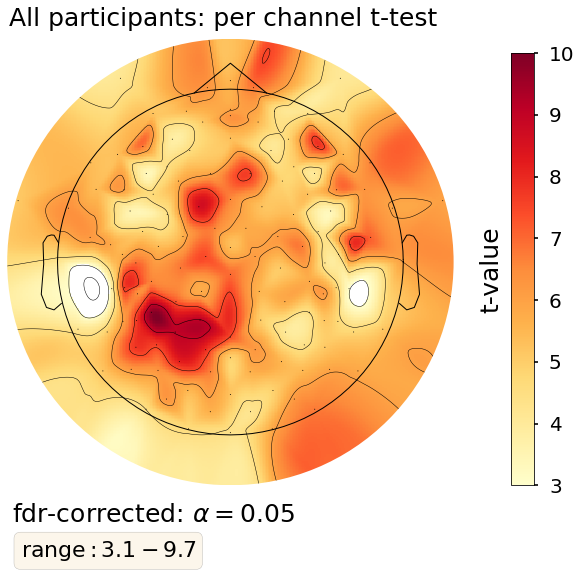

In [273]:
fig, cbar_ax, clb = plot_brain(mask_bh, info,subject='All participants',params=params, title=r'per channel t-test',show=True,all_subjects=True,vmin=vmin, cbar_label="t-value", vmax=int(vmax),fname=(fig_fname_t+'.png'))

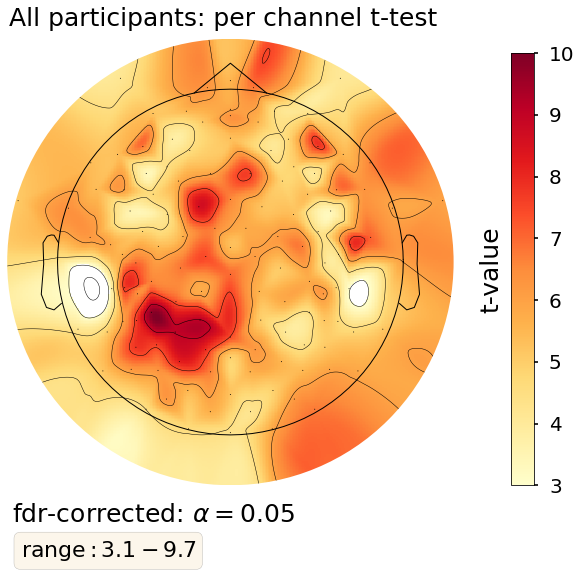

In [ ]:
fig, cbar_ax, clb = plot_brain(mask_bh, info,subject='All participants',params=params, title=r'per channel t-test',show=True,all_subjects=True,vmin=vmin, cbar_label="t-value", vmax=int(vmax),fname=(fig_fname_t+'.png'))

ValueError: Number of channels in the Info object (129) and the data array (28) do not match. Pick Info with e.g. mne.pick_info and mne.io.pick.channel_indices_by_type.

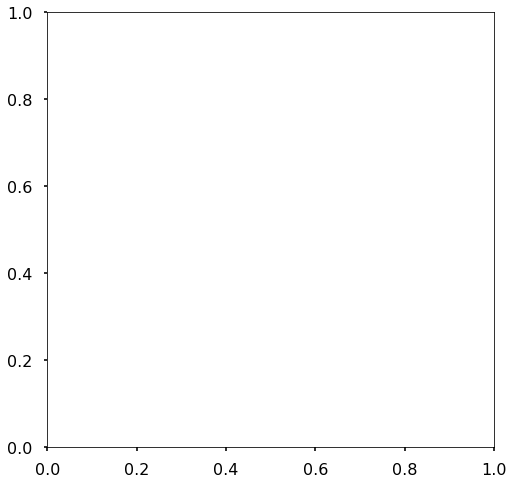

In [256]:
# fig, cbar_ax, colbr = plot_acc_brain(acc, info,subject='All Participants',params=params, title='corrected results',show=True,all_subjects=True,vmin=int(55), vmax=int(vmax))

In [41]:
ind_bh.shape

(129,)

In [45]:
acc.shape

(28, 129, 1)

In [47]:
acc_m.shape

(129,)

In [70]:
max(mask_bh)

0.6714285714285716

In [202]:
clb.ax.set_yticklabels(fontsize=25)

In [ ]:

import matplotlib.colors as mcolors

data = np.random.rand(10,10) * 2 - 1

# sample the colormaps that you want to use. Use 128 from each so we get 256
# colors in total
colors1 = plt.cm.YlOrRd(np.linspace(55, 70, 128))
colors2 = plt.cm.gist_heat_r(np.linspace(0, 55, 128))

# combine them and build a new colormap
colors = np.vstack((colors1, colors2))
mymap = mcolors.LinearSegmentedColormap.from_list('my_colormap', colors)

plt.pcolor(data, cmap=mymap)
plt.colorbar()
plt.show()

In [95]:
colors1 = plt.cm.YlOrRd(np.linspace(50.00001,70,128)) 
# colors = zip(np.linspace(0,50,128),colors) 
# colors2 = [ (0.5,"#FFFFFF"),(0.0,"#FFFFFF")] 
# colors = np.vstack((colors1, colors2))
colors1 = plt.cm.YlOrRd(np.linspace(50.00001,70,128)) 
cmap = mpl.colors.LinearSegmentedColormap.from_list('mycmap', colors1)
cmap.set_under(color="#FFFFFF")


In [98]:
cmap.set_under(color="#FFFFFF")

In [87]:
clb.set_ticks([55,60,65,70],update_ticks=True)

/home/tpirnia/miniconda3/envs/python36c2/lib/python3.6/site-packages/ipykernel_launcher.py:1: MatplotlibDeprecationWarning: 
The get_clim function was deprecated in Matplotlib 3.1 and will be removed in 3.3. Use ScalarMappable.get_clim instead.
  """Entry point for launching an IPython kernel.


(55.0, 70.0)

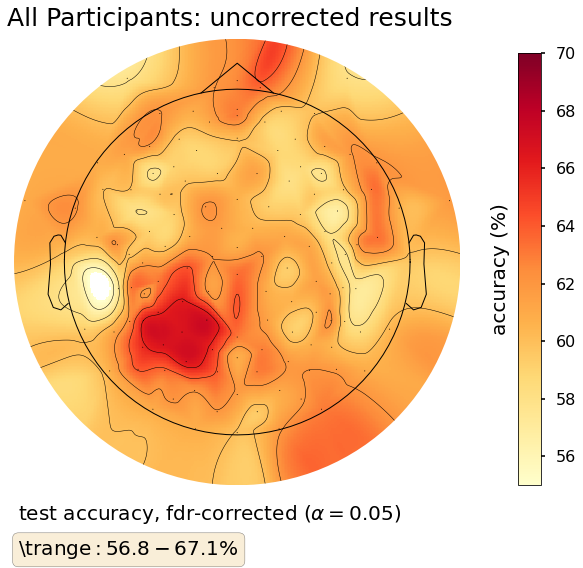

In [164]:
fig, cbar_ax, colbr = plot_acc_brain(mask_bh, info,subject='All Participants',params=params, title='uncorrected results',show=True,all_subjects=True,vmin=int(55), vmax=int(vmax))

In [ ]:
fig, cbar_ax, colbr = plot_acc_brain(acc, info,subject='All Participants',params=params, title='uncorrected results',show=True,all_subjects=True,vmin=int(55), vmax=int(vmax),fname=fig_fname_a+'_YlOrRd.png')

In [ ]:
fig, cbar_ax, colbr = plot_acc_brain(tval, info,subject='All Participants',params=params, title='uncorrected results',show=True,all_subjects=True,vmin=int(55), vmax=int(vmax),fname=fig_fname_t+'_YlOrRd.png')

_______

{"data":{"layout-restorer:data":{"main":{"dock":{"type":"tab-area","currentIndex":1,"widgets":["console:data/EEGWS/code/console-1-d48b6e49-ca71-4afd-8020-f632ac70a7c8","notebook:data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb"]},"mode":"multiple-document","current":"notebook:data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb"},"left":{"collapsed":false,"current":"running-sessions","widgets":["filebrowser","running-sessions","command-palette","jp-property-inspector","tab-manager","extensionmanager.main-view"]},"right":{"collapsed":true,"widgets":[]}},"file-browser-filebrowser:cwd":{"path":"data/EEGWS/code/troubleshoot/notebooks"},"console:data/EEGWS/code/console-1-d48b6e49-ca71-4afd-8020-f632ac70a7c8":{"data":{"path":"data/EEGWS/code/console-1-d48b6e49-ca71-4afd-8020-f632ac70a7c8","name":"Console 1","kernelPreference":{"name":"python3"}}},"notebook:data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb":{"data":{"path":"data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb","factory":"Notebook"}}},"metadata":{"id":"/lab/workspaces/chapter1_bychannel_sig"}}

{"data":{"layout-restorer:data":{"main":{"dock":{"type":"tab-area","currentIndex":1,"widgets":["console:data/EEGWS/code/console-1-d48b6e49-ca71-4afd-8020-f632ac70a7c8","notebook:data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb"]},"mode":"multiple-document","current":"notebook:data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb"},"left":{"collapsed":false,"current":"running-sessions","widgets":["filebrowser","running-sessions","command-palette","jp-property-inspector","tab-manager","extensionmanager.main-view"]},"right":{"collapsed":true,"widgets":[]}},"file-browser-filebrowser:cwd":{"path":"data/EEGWS/code/troubleshoot/notebooks"},"console:data/EEGWS/code/console-1-d48b6e49-ca71-4afd-8020-f632ac70a7c8":{"data":{"path":"data/EEGWS/code/console-1-d48b6e49-ca71-4afd-8020-f632ac70a7c8","name":"Console 1","kernelPreference":{"name":"python3"}}},"notebook:data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb":{"data":{"path":"data/EEGWS/maybe_repo/instructions/ch2_crossclassify_context_run_permutations.ipynb","factory":"Notebook"}}},"metadata":{"id":"/lab/workspaces/chapter1_bychannel_sig"}}

{
 "argv": [
  "/home/tpirnia/miniconda3/envs/python36c2/bin/python",
  "-m",
  "ipykernel_launcher",
  "-f",
  "{connection_file}"
 ],
 "display_name": "Python 3",
 "language": "python"
}

In [ ]:
conda install numpy ```bash
conda install numba  numpy scipy numba cudatoolkit matplotlib pandas  scikit-learn scikit-image tabulate tmux
jupyter ipykernel ipython ipywidgets h5py hdf5

conda create --name pynew -c conda-forge jupyterlab numpy scipy matplotlib pandas scikit-learn seaborn itertools tmux joblib

conda install -c conda-forge jupyterlab



  - pip:
    - backports-zoneinfo==0.2.1
    - cachetools==4.2.0
    - ctparse==0.3.6
    - dataclasses==0.8
    - dateparser==1.1.3
    - filelock==3.4.1
    - idna-ssl==1.1.0
    - imageio==2.9.0
    - importlib-resources==5.4.0
    - loam==0.3.1
    - mne==0.22.0
    - networkx==2.5
    - nodejs==0.1.1
    - optional-django==0.1.0
    - pillow==8.0.1
    - pip-chill==1.0.0
    - pip-date==1.0.3
    - py-spy==0.3.3
    - pyasn1==0.4.8
    - pyasn1-modules==0.2.8
    - pyspnego==0.5.4
    - pytz-deprecation-shim==0.1.0.post0
    - pywavelets==1.1.1
    - regex==2022.3.2
    - rsa==4.6
    - scaleogram==0.9.5
    - scikit-image==0.17.2
    - seaborn==0.11.2
    - seglearn==1.2.3
    - setuptools-scm==3.5.0
    - smbprotocol==1.9.0
    - tifffile==2020.9.3
    - tzdata==2023.3
    - tzlocal==4.2
    - urllib3==1.26.2
```

- running - conda update -n python36c2_backup jupyterlab
- tbd - conda update -c anaconda -n python36c2_backup scipy

- conda install -c anaconda scipy